
=== Method 1: Laplacian of Gaussian ===
sigma range used: 1.00 to 45.00   (radius 1.4 to 63.6 px)
blobs detected: 264
rank      x      y    sigma   radius
   1    281    335    14.83    20.97
   2      0    278    14.83    20.97
   3    177    333    12.65    17.89
   4    180    260    12.65    17.89
   5    106    257    10.80    15.27

=== Method 2: Scale-space extrema (DoG) ===
sigma range used: 1.08 to 41.70   (radius 1.5 to 59.0 px)
blobs detected: 229
rank      x      y    sigma   radius
   1    282    337    16.73    23.65
   2      0    278    14.36    20.31
   3    177    333    12.33    17.44
   4    106    256    12.33    17.44
   5     65    283    12.33    17.44
(DoG: Gaussian levels sigma = 1.00 ... 45.00, k = 1.1645)


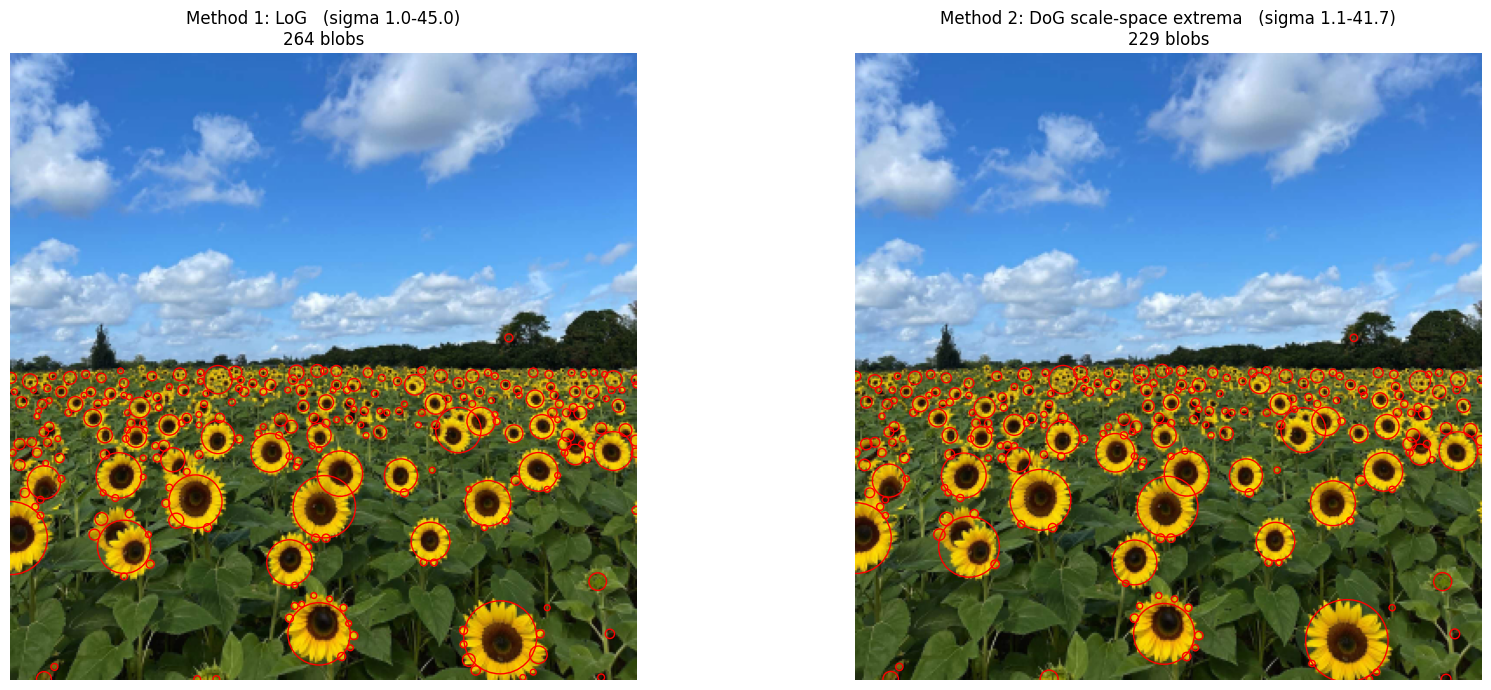

In [34]:
"""
EN3160 Assignment 2 - Question 1
Blob (sunflower) detection using BOTH methods named in the question.
cv2.HoughCircles is NOT used.

Method 1 : Laplacian of Gaussian (LoG)
    The image is convolved with an explicit scale-normalised LoG kernel
        sigma^2 * LoG(x, y; sigma)
    at a set of scales. Blobs are the extrema of the response over (x, y, sigma).

Method 2 : Scale-space extrema detection (Difference of Gaussians, DoG)
    A Gaussian scale-space  G(sigma_i) * I  with sigma_i = sigma_min * k^i  is built.
    Adjacent levels are subtracted, D_i = G(sigma_{i+1}) - G(sigma_i), which approximates
    (k-1) * sigma^2 * LoG. Blobs are the 3x3x3 extrema of the DoG stack (as in SIFT).

For both methods a blob found at scale sigma is drawn as a circle of radius r = sqrt(2) * sigma
(a disc of radius r gives its strongest LoG response at sigma = r / sqrt(2)).
"""
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# ----------------------------------------------------------------------------
# Parameters (tune these for the image)
# ----------------------------------------------------------------------------
IMG_PATH = 'a2images/the_berry_farms_sunflower_field.jpeg'
SIGMA_MIN = 1.0          # smallest sigma -> smallest radius = sqrt(2) * SIGMA_MIN
SIGMA_MAX = 45.0         # largest sigma (raise it if the biggest circles sit at this value)
N_SCALES = 25            # number of scales (geometric progression, same for both methods)
THRESH_LOG = 0.12        # fraction of the max response used as threshold (LoG)
THRESH_DOG = 0.12        # fraction of the max response used as threshold (DoG)
BRIGHT_BLOBS = True     # are the blobs brighter than their surroundings?
OVERLAP = 1            # circles closer than OVERLAP*(r1+r2) are merged (weaker one dropped)
N_LARGEST = 5            # how many of the largest circles to report
CHANNEL = 'yellow'       # 'yellow' = (R+G)/2 - B ; 'gray' = plain grayscale

# ----------------------------------------------------------------------------
# Common helpers
# ----------------------------------------------------------------------------

def to_detection_channel(im_bgr):
    """Single-channel float image in which the blobs of interest are BRIGHT."""
    f = im_bgr.astype(np.float64) / 255.0
    b, g, r = f[..., 0], f[..., 1], f[..., 2]
    if CHANNEL == 'yellow':
        rc = r / (r + g + b + 0.03)                 # red chromaticity: ignores brightness
        return np.clip((rc - 0.38) / 0.2, 0.0, 1.0)
    return cv.cvtColor(im_bgr, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0

def extrema_3d(resp, thr, bright=True):
    """3x3x3 local extrema of a (n_scales, H, W) response stack above a threshold.
    Returns arrays (k, y, x) of scale index and pixel position."""
    r = -resp if bright else resp                  # bright blob -> negative LoG/DoG -> flip
    is_max = (r == maximum_filter(r, size=(3, 3, 3)))
    keep = is_max & (r > thr * r.max())
    keep[0] = False                                # first/last scale are 'maxima' only because
    keep[-1] = False                               # of the border -> not true scale-space extrema
    k, y, x = np.nonzero(keep)
    return k, y, x, r[k, y, x]


def suppress_overlaps(blobs, overlap=OVERLAP):
    """blobs: list of (x, y, sigma, response). Keep the strongest of overlapping circles."""
    kept = []
    for x, y, s, resp in sorted(blobs, key=lambda b: -b[3]):
        r = np.sqrt(2) * s
        # drop a blob if its centre lies inside a stronger kept circle (or vice versa)
        if all(np.hypot(x - xk, y - yk) >= overlap * max(r, np.sqrt(2) * sk)
               for xk, yk, sk, _ in kept):
            kept.append((x, y, s, resp))
    return kept


# ----------------------------------------------------------------------------
# Method 1: LoG
# ----------------------------------------------------------------------------
def log_kernel(sigma):
    """Explicit Laplacian-of-Gaussian kernel (zero-mean, truncated at 3*sigma... 4*sigma)."""
    half = int(np.ceil(4 * sigma))
    ax = np.arange(-half, half + 1, dtype=np.float64)
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx ** 2 + yy ** 2
    k = -(1.0 / (np.pi * sigma ** 4)) * (1.0 - r2 / (2 * sigma ** 2)) * np.exp(-r2 / (2 * sigma ** 2))
    return k - k.mean()                            # force zero DC response


def method_log(gray, sigmas):
    stack = np.stack([(s ** 2) * cv.filter2D(gray, cv.CV_64F, log_kernel(s),
                                              borderType=cv.BORDER_REFLECT)
                      for s in sigmas])            # scale-normalised LoG responses
    k, y, x, resp = extrema_3d(stack, THRESH_LOG, BRIGHT_BLOBS)
    blobs = [(int(xi), int(yi), float(sigmas[ki]), float(v)) for ki, yi, xi, v in zip(k, y, x, resp)]
    return suppress_overlaps(blobs)


# ----------------------------------------------------------------------------
# Method 2: DoG scale-space extrema
# ----------------------------------------------------------------------------
def method_dog(gray, sigmas_edges):
    """sigmas_edges has N+1 values (geometric); the N DoG levels are between neighbours."""
    gauss = [cv.GaussianBlur(gray, (0, 0), s) for s in sigmas_edges]      # Gaussian scale-space
    dog = np.stack([gauss[i + 1] - gauss[i] for i in range(len(gauss) - 1)])
    # characteristic scale of D_i is the geometric mean of the two sigmas it is built from
    sig_level = np.sqrt(sigmas_edges[:-1] * sigmas_edges[1:])
    k, y, x, resp = extrema_3d(dog, THRESH_DOG, BRIGHT_BLOBS)
    blobs = [(int(xi), int(yi), float(sig_level[ki]), float(v)) for ki, yi, xi, v in zip(k, y, x, resp)]
    return suppress_overlaps(blobs), sig_level


# ----------------------------------------------------------------------------
# Reporting / drawing
# ----------------------------------------------------------------------------
def report(name, blobs, sig_lo, sig_hi):
    print(f'\n=== {name} ===')
    print(f'sigma range used: {sig_lo:.2f} to {sig_hi:.2f}   '
          f'(radius {np.sqrt(2) * sig_lo:.1f} to {np.sqrt(2) * sig_hi:.1f} px)')
    print(f'blobs detected: {len(blobs)}')
    print(f'{"rank":>4} {"x":>6} {"y":>6} {"sigma":>8} {"radius":>8}')
    for i, (x, y, s, _) in enumerate(sorted(blobs, key=lambda b: -b[2])[:N_LARGEST], 1):
        print(f'{i:>4} {x:>6} {y:>6} {s:>8.2f} {np.sqrt(2) * s:>8.2f}')


def draw(ax, im_rgb, blobs, title):
    ax.imshow(im_rgb)
    for x, y, s, _ in blobs:
        ax.add_patch(plt.Circle((x, y), np.sqrt(2) * s, color='r', fill=False, lw=1.0))
    ax.set_title(f'{title}\n{len(blobs)} blobs')
    ax.axis('off')


def main():
    im = cv.imread(IMG_PATH, cv.IMREAD_REDUCED_COLOR_4)
    if im is None:
        raise FileNotFoundError(IMG_PATH)
    im_rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)
    gray = to_detection_channel(im)
    cv.imwrite('q1_detection_channel.png', (gray * 255).astype(np.uint8))  # for the report

    # same geometric sigma grid for both methods
    sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)

    # Method 1: LoG on the N sigmas
    blobs_log = method_log(gray, sigmas)
    report('Method 1: Laplacian of Gaussian', blobs_log, sigmas[0], sigmas[-1])

    # Method 2: DoG built from N+1 Gaussian levels (so N DoG levels span the same range)
    k = (SIGMA_MAX / SIGMA_MIN) ** (1.0 / N_SCALES)
    sig_edges = SIGMA_MIN * k ** np.arange(N_SCALES + 1)
    blobs_dog, sig_level = method_dog(gray, sig_edges)
    report('Method 2: Scale-space extrema (DoG)', blobs_dog, sig_level[0], sig_level[-1])
    print(f'(DoG: Gaussian levels sigma = {sig_edges[0]:.2f} ... {sig_edges[-1]:.2f}, k = {k:.4f})')

    # ---- side-by-side comparison figure ----
    fig, axs = plt.subplots(1, 2, figsize=(18, 7))
    draw(axs[0], im_rgb, blobs_log, f'Method 1: LoG   (sigma {sigmas[0]:.1f}-{sigmas[-1]:.1f})')
    draw(axs[1], im_rgb, blobs_dog, f'Method 2: DoG scale-space extrema   '
                                    f'(sigma {sig_level[0]:.1f}-{sig_level[-1]:.1f})')
    plt.tight_layout()
    plt.savefig('q1_result.png', dpi=150)
    plt.show()


if __name__ == '__main__':
    main()